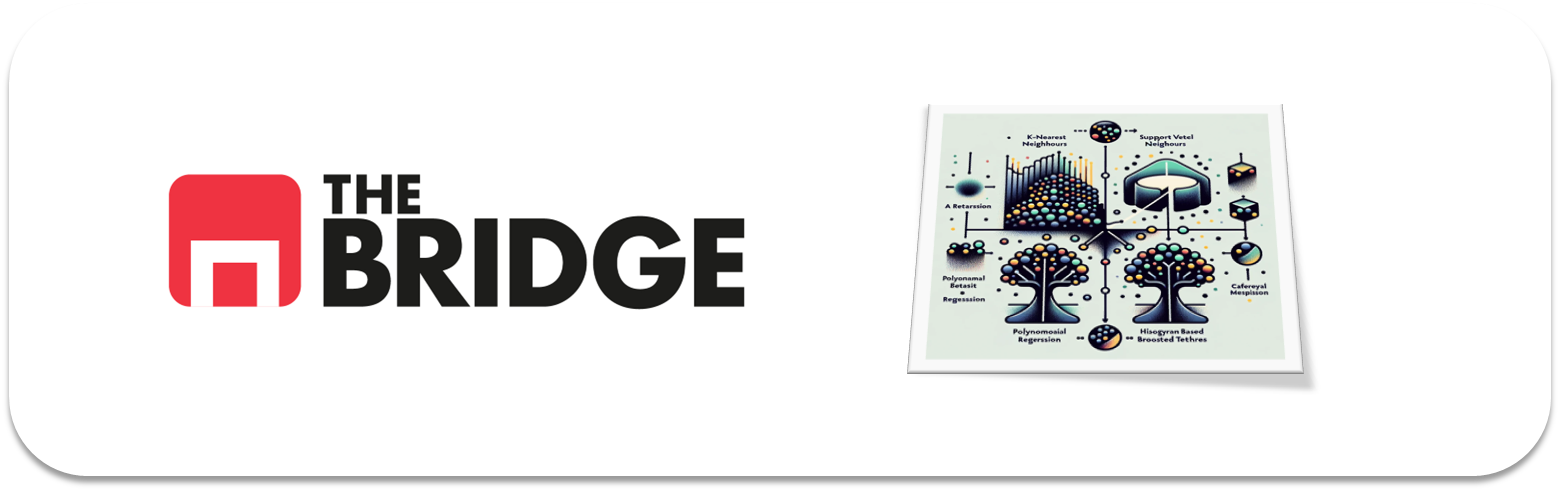

# Otros Modelos: Support Vector Machine

### Concepto y modelado lineal para clasificación


En esta primera parte te explico muy por encima el concepto que hay detrás del modelo, pero no es fundamental que lo memorices.

Partimos de este conjunto de datos y queremos hacer un modelo de clasificación

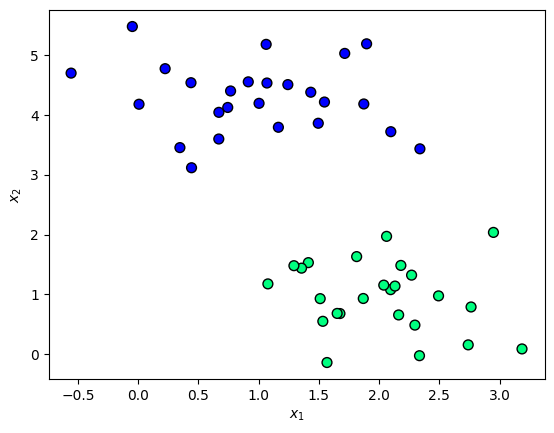

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.datasets import make_blobs
X, y = make_blobs(n_samples=50, centers=2,
                  random_state=0, cluster_std=0.60)
plt.scatter(X[:, 0], X[:, 1], c=y, s=50, cmap='winter',edgecolors='k');
plt.xlabel('$x_1$')
plt.ylabel('$x_2$');

Existen infinitos separadores (modelos) que separan perfectamente ambas clases

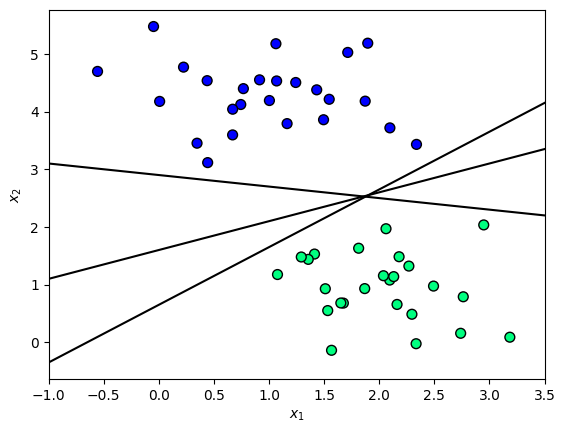

In [2]:
xfit = np.linspace(-1, 3.5)
plt.scatter(X[:, 0], X[:, 1], c=y, s=50, cmap='winter',edgecolors='k')


for m, b in [(1, 0.65), (0.5, 1.6), (-0.2, 2.9)]:
    plt.plot(xfit, m * xfit + b, '-k')

plt.xlim(-1, 3.5);
plt.xlabel('$x_1$')
plt.ylabel('$x_2$');

¿Cuál es el mejor separador? 

Empecemos analizando cuál es el separador de la regresión logística

In [3]:
from sklearn.linear_model import LogisticRegression

lr = LogisticRegression(random_state=42)
lr.fit(X,y)
lr.intercept_, lr.coef_

(array([4.81433718]), array([[ 0.57337249, -2.18045686]]))

$\Large y = \theta(4.81 + 0.573x_1 - 2.18x_2)$, donde $\Large \theta$ es la función sigmoide:

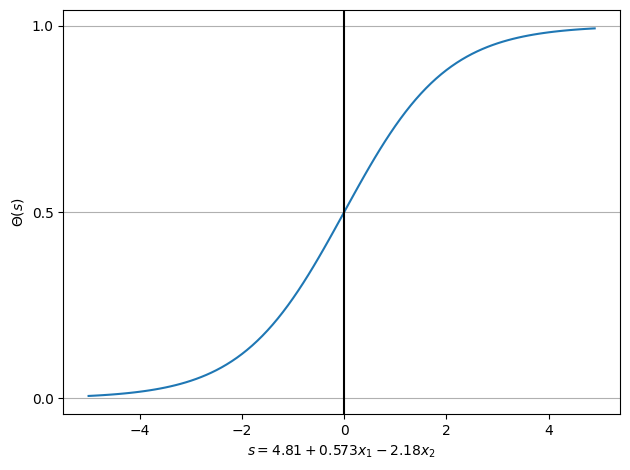

In [4]:
def sigmoid(z):
    return 1 / (1 + np.exp(-z))
z = np.arange(-5, 5, 0.1)
phi_z = sigmoid(z)
 
plt.plot(z, phi_z)
plt.axvline(0.0, color='k')
plt.xlabel('$s=4.81 + 0.573x_1 - 2.18x_2$')
plt.ylabel(r'$\Theta(s)$')
plt.yticks([0.0, 0.5, 1.0])
ax = plt.gca()
ax.yaxis.grid(True)
plt.tight_layout()
plt.show()

En regresión logística, la predicción queda determinada por la ecuación $\theta(s)=\theta(w_0+w_1x_1+w_2x_2+...+w_Nx_N)$. Cuando $s=0$,  $\theta(s)=0.5$, que suele ser el umbral para clasificar una categoría u otra. 

En este ejemplo $s=4.81 + 0.573x_1 - 2.18x_2$. Si igualamos a cero, obtenemos la ecuación de la recta separadora:

$4.81 + 0.573x_1 - 2.18x_2=0$  
  
$2.18x_2 = 0.573x_1 + 4.81$   
  
$x_2=\frac{0.573}{2.18}x_1 + \frac{4.81}{2.18}$
  
$x_2 = 0.263x_1 + 2.206 $

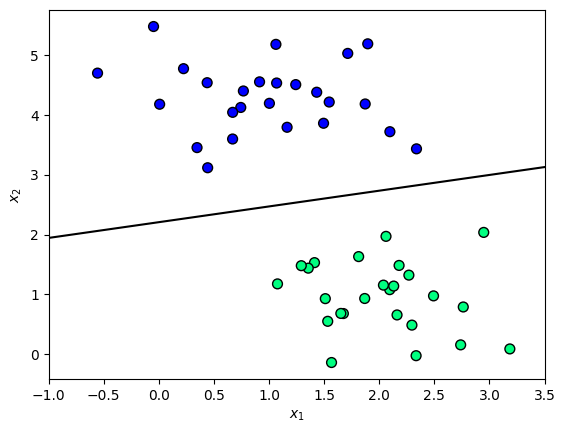

In [5]:
xfit = np.linspace(-1, 3.5)
plt.scatter(X[:, 0], X[:, 1], c=y, s=50, cmap='winter',edgecolors='k')
m=0.263
b=2.206
plt.plot(xfit, m * xfit + b, '-k')
plt.xlim(-1, 3.5);
plt.xlabel('$x_1$')
plt.ylabel('$x_2$');

**Support vector machines** busca establecer un separador con el mayor margen posible a las muestras más cercanas

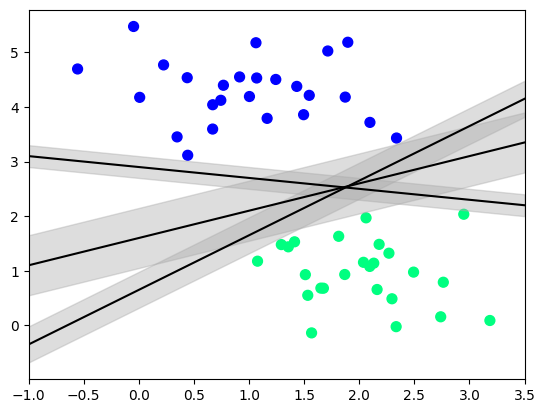

In [6]:
xfit = np.linspace(-1, 3.5)
plt.scatter(X[:, 0], X[:, 1], c=y, s=50, cmap='winter')

for m, b, d in [(1, 0.65, 0.33), (0.5, 1.6, 0.55), (-0.2, 2.9, 0.2)]:
    yfit = m * xfit + b
    plt.plot(xfit, yfit, '-k')
    plt.fill_between(xfit, yfit - d, yfit + d, edgecolor='none',
                     color='#AAAAAA', alpha=0.4)

plt.xlim(-1, 3.5);

La recta separadora que maximice este margen será escogida como el mejor modelo.

In [7]:
from sklearn.svm import SVC # "support vector classifier"

model = SVC(kernel='linear', C=1e10)
model.fit(X,y)

,"C C: float, default=1.0Regularization parameter. The strength of the regularization isinversely proportional to C. Must be strictly positive. The penaltyis a squared l2 penalty. For an intuitive visualization of the effectsof scaling the regularization parameter C, see:ref:`sphx_glr_auto_examples_svm_plot_svm_scale_c.py`.",10000000000.0
,"kernel kernel: {'linear', 'poly', 'rbf', 'sigmoid', 'precomputed'} or callable, default='rbf'Specifies the kernel type to be used in the algorithm. Ifnone is given, 'rbf' will be used. If a callable is given it is used topre-compute the kernel matrix from data matrices; that matrix should bean array of shape ``(n_samples, n_samples)``. For an intuitivevisualization of different kernel types see:ref:`sphx_glr_auto_examples_svm_plot_svm_kernels.py`.",'linear'
,"degree degree: int, default=3Degree of the polynomial kernel function ('poly').Must be non-negative. Ignored by all other kernels.",3
,"gamma gamma: {'scale', 'auto'} or float, default='scale'Kernel coefficient for 'rbf', 'poly' and 'sigmoid'.- if ``gamma='scale'`` (default) is passed then it uses 1 / (n_features * X.var()) as value of gamma,- if 'auto', uses 1 / n_features- if float, must be non-negative... versionchanged:: 0.22 The default value of ``gamma`` changed from 'auto' to 'scale'.",'scale'
,"coef0 coef0: float, default=0.0Independent term in kernel function.It is only significant in 'poly' and 'sigmoid'.",0.0
,"shrinking shrinking: bool, default=TrueWhether to use the shrinking heuristic.See the :ref:`User Guide <shrinking_svm>`.",True
,"probability probability: bool, default=FalseWhether to enable probability estimates. This must be enabled priorto calling `fit`, will slow down that method as it internally uses5-fold cross-validation, and `predict_proba` may be inconsistent with`predict`. Read more in the :ref:`User Guide <scores_probabilities>`...deprecated:: 1.9 The `probability` parameter is deprecated and will be removed in 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`.",'deprecated'
,"tol tol: float, default=1e-3Tolerance for stopping criterion.",0.001
,"cache_size cache_size: float, default=200Specify the size of the kernel cache (in MB).",200
,"class_weight class_weight: dict or 'balanced', default=NoneSet the parameter C of class i to class_weight[i]*C forSVC. If not given, all classes are supposed to haveweight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.",None
,"verbose verbose: bool, default=FalseEnable verbose output. Note that this setting takes advantage of aper-process runtime setting in libsvm that, if enabled, may not workproperly in a multithreaded context.",False


Fíjate por un segundo antes de seguir que existe ese argumento kernel (luego volveremos a él)

In [8]:
def plot_svc_decision_function(model, ax=None, plot_support=True):
    """Plot the decision function for a 2D SVC"""
    if ax is None:
        ax = plt.gca()
    xlim = ax.get_xlim()
    ylim = ax.get_ylim()
    
    # create grid to evaluate model
    x = np.linspace(xlim[0], xlim[1], 30)
    y = np.linspace(ylim[0], ylim[1], 30)
    Y, X = np.meshgrid(y, x)
    xy = np.vstack([X.ravel(), Y.ravel()]).T
    P = model.decision_function(xy).reshape(X.shape)
    
    # plot decision boundary and margins
    ax.contour(X, Y, P, colors='k',
               levels=[-1, 0, 1], alpha=0.5,
               linestyles=['--', '-', '--'])
    
    # plot support vectors
    if plot_support:
        ax.scatter(model.support_vectors_[:, 0],
                   model.support_vectors_[:, 1],
                   s=300, linewidth=1,facecolors='none', edgecolors='r');
    ax.set_xlim(xlim)
    ax.set_ylim(ylim)

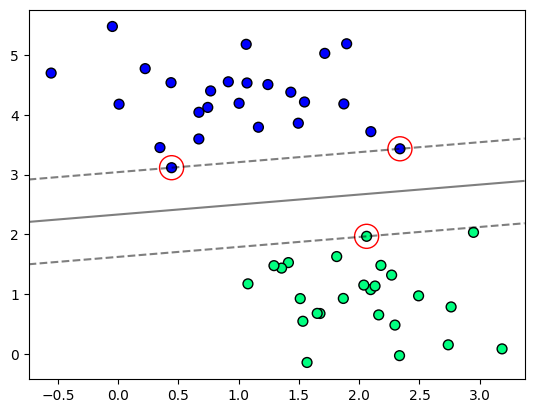

In [9]:
plt.scatter(X[:, 0], X[:, 1], c=y, s=50, cmap='winter',edgecolors='k');
plot_svc_decision_function(model);


Esta recta separadora maximiza el margen entre los dos conjuntos de puntos. Fíjate en que algunos de los puntos están justo en el margen, indicados con círculos rojos. Estos puntos son los vectores de soporte, que dan nombre al algoritmo.

In [10]:
model.support_vectors_

array([[0.44359863, 3.11530945],
       [2.33812285, 3.43116792],
       [2.06156753, 1.96918596]])

Si pintamos la recta de la regresión logística que calculamos anteriormente, vemos que no es exactamente la misma

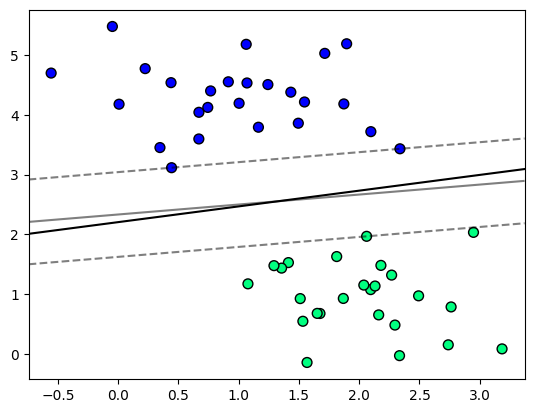

In [11]:
# Datos
plt.scatter(X[:,0], X[:,1], c=y, s=50, cmap='winter', edgecolors='k')

# SVM
plot_svc_decision_function(model, plot_support=False)

# Regresión Logística
xfit = np.linspace(-1, 3.5)
m=0.263
b=2.206
plt.plot(xfit, m * xfit + b, '-k')

### Matizaciones

**1. Sensible a la escala.** Igual que el KNN, se basa en distancias (de los puntos al separador). Mira qué pasa con cuatro puntos en los que una feature va de 1 a 5 y la otra de 20 a 80:

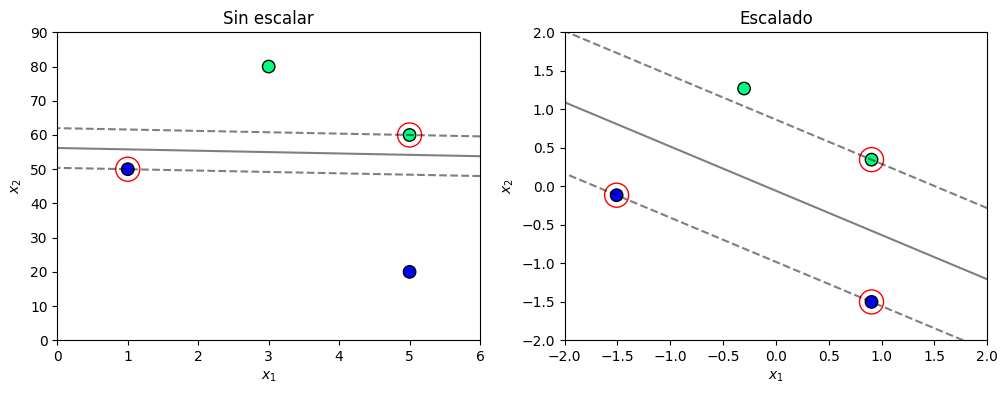

In [12]:
from sklearn.preprocessing import StandardScaler

X_escala = np.array([[1, 50], [5, 20], [3, 80], [5, 60]], dtype=float)
y_escala = np.array([0, 0, 1, 1])
X_escala_esc = StandardScaler().fit_transform(X_escala)

fig, axs = plt.subplots(1, 2, figsize=(12, 4))
for ax, X_p, limites, titulo in [(axs[0], X_escala, (0, 6, 0, 90), "Sin escalar"),
                                 (axs[1], X_escala_esc, (-2, 2, -2, 2), "Escalado")]:
    svm_p = SVC(kernel="linear", C=100).fit(X_p, y_escala)
    ax.scatter(X_p[:, 0], X_p[:, 1], c=y_escala, s=80, cmap='winter', edgecolors='k')
    ax.set_xlim(limites[0], limites[1]); ax.set_ylim(limites[2], limites[3])
    plot_svc_decision_function(svm_p, ax=ax)
    ax.set_title(titulo); ax.set_xlabel("$x_1$"); ax.set_ylabel("$x_2$")
plt.show()

Sin escalar, la feature $x_2$ (de 20 a 80) domina las distancias y el SVM se conforma con una calle casi horizontal y muy estrecha si la medimos en unidades de $x_1$. Tras escalar, las dos features cuentan por igual y el margen es mucho más amplio y razonable.

**2. Muy sensible a outliers.** Usamos dos especies del dataset iris (longitud y anchura del pétalo), que se separan perfectamente, y le añadimos un único punto raro:

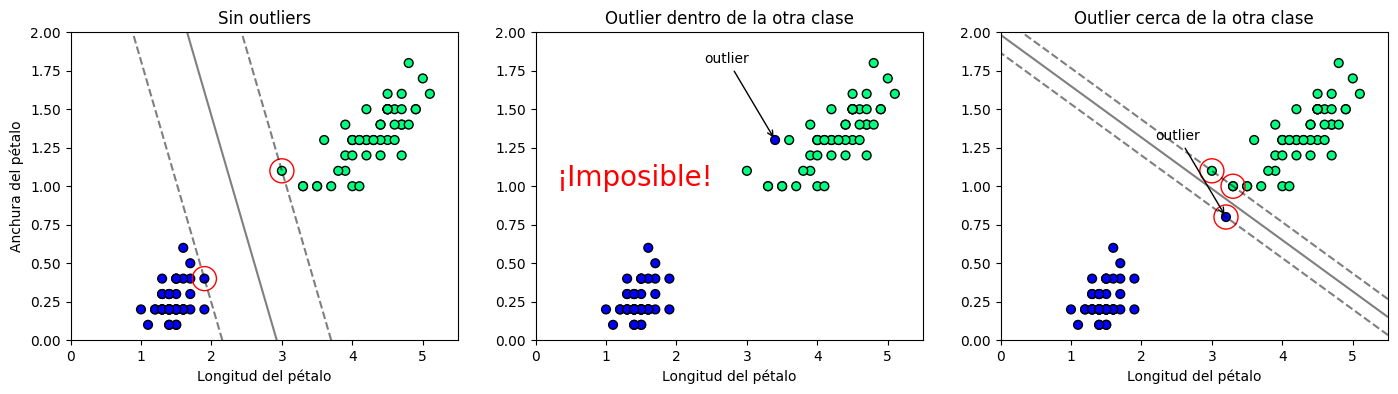

In [13]:
from sklearn.datasets import load_iris

iris = load_iris()
X_iris = iris.data[:, 2:4]  # longitud y anchura del pétalo
y_iris = iris.target

mascara = (y_iris == 0) | (y_iris == 1)  # setosa (0) y versicolor (1)
X_sv, y_sv = X_iris[mascara], y_iris[mascara]

outlier_1 = [3.4, 1.3]  # una setosa metida entre las versicolor
outlier_2 = [3.2, 0.8]  # una setosa rara, cerca de las versicolor
X_out1, y_out1 = np.vstack([X_sv, outlier_1]), np.append(y_sv, 0)
X_out2, y_out2 = np.vstack([X_sv, outlier_2]), np.append(y_sv, 0)

fig, axs = plt.subplots(1, 3, figsize=(17, 4))
casos = [(X_sv, y_sv, None, "Sin outliers"),
         (X_out1, y_out1, outlier_1, "Outlier dentro de la otra clase"),
         (X_out2, y_out2, outlier_2, "Outlier cerca de la otra clase")]
for i, (ax, (X_p, y_p, outlier, titulo)) in enumerate(zip(axs, casos)):
    ax.scatter(X_p[:, 0], X_p[:, 1], c=y_p, s=40, cmap='winter', edgecolors='k')
    ax.set_xlim(0, 5.5); ax.set_ylim(0, 2)
    ax.set_title(titulo); ax.set_xlabel("Longitud del pétalo")
    if outlier is not None:
        ax.annotate("outlier", xy=outlier, xytext=(outlier[0] - 1, outlier[1] + 0.5), arrowprops=dict(arrowstyle="->"))
    if i == 1:
        ax.text(0.3, 1.0, "¡Imposible!", fontsize=20, color="red")
    else:
        plot_svc_decision_function(SVC(kernel="linear", C=1e10).fit(X_p, y_p), ax=ax)
axs[0].set_ylabel("Anchura del pétalo")
plt.show()

- Sin outliers, la calle es ancha.
- Si el outlier está **dentro** de la otra clase, es imposible encontrar un margen estricto (sin ningún punto dentro de la calle).
- Si el outlier está **cerca** de la otra clase, el SVM lo consigue, pero la calle se estrecha muchísimo y la frontera cambia por completo por culpa de un solo punto. Es poco probable que ese modelo generalice bien.

Hay que tratar los outliers (quitarlos y, si hace falta, predecir esos puntos con otro modelo) o bajar el valor de C, que es lo que vemos a continuación.

**3. El hiperparámetro C: margen estricto o margen blando.** En datos reales casi nunca existe un margen "limpio" entre las clases. Por eso el SVM tiene un hiperparámetro C que permite que algunos puntos invadan el margen (o incluso queden en el lado equivocado):

- C alto: muy estricto, casi no permite puntos dentro del margen. Margen estrecho y más riesgo de overfitting.
- C bajo: más tolerante. Margen más ancho, que suele generalizar mejor aunque cometa algún error más en train.

Lo vemos con otras dos especies de iris, versicolor y virginica, que sí se solapan un poco (ya escaladas):

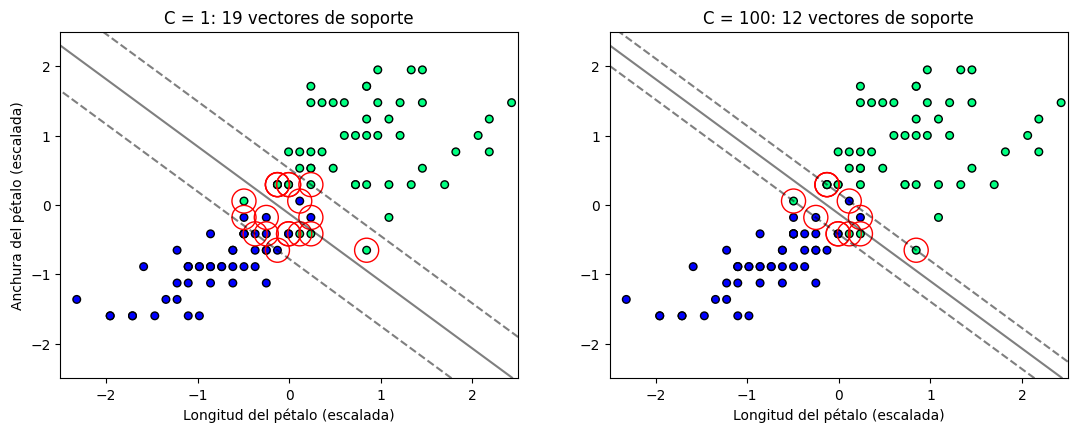

In [14]:
mascara = (y_iris == 1) | (y_iris == 2)  # versicolor y virginica
X_vv = StandardScaler().fit_transform(X_iris[mascara])
y_vv = (y_iris[mascara] == 2).astype(int)  # 1 = virginica

fig, axs = plt.subplots(1, 2, figsize=(13, 4.5))
for ax, C in zip(axs, [1, 100]):
    svm_c = SVC(kernel="linear", C=C).fit(X_vv, y_vv)
    ax.scatter(X_vv[:, 0], X_vv[:, 1], c=y_vv, s=30, cmap='winter', edgecolors='k')
    ax.set_xlim(-2.5, 2.5); ax.set_ylim(-2.5, 2.5)
    plot_svc_decision_function(svm_c, ax=ax)
    ax.set_title(f"C = {C}: {len(svm_c.support_vectors_)} vectores de soporte")
    ax.set_xlabel("Longitud del pétalo (escalada)")
axs[0].set_ylabel("Anchura del pétalo (escalada)")
plt.show()

Con C = 1 la calle es ancha y tiene muchos puntos dentro (19 vectores de soporte); con C = 100 la calle es mucho más estrecha y solo deja entrar a 12. Las dos rectas separadoras son parecidas, pero la de C = 1 es la que más probablemente generalizará mejor. En la práctica, C se ajusta con validación cruzada, como cualquier otro hiperparámetro.

En general no es un modelo que nosotros vayamos a utilizar, pero puede que tú sí quieras probarlo y alguna vez lo necesites. [Aquí](https://scikit-learn.org/stable/modules/svm.html) tienes una referencia para profundizar más. Nosotros vamos a limitarnos a presentar otros "kernels" y su concepto y ahí lo dejamos.

### Kernels: SVM como clasificadores no lineales

Una forma un poco "grosera" de ver la generalización de este tipo de modelos es considerar los conceptos del apartado anterior, pero transformando antes los datos (como hacíamos con la transformación a polinomio de las regresiones lineales en la unidad de Regresión Polinómica y Regularización). A esa transformación previa se le denomina "kernelización" o sea aplicación de un kernel o transformación. De hecho SVM tiene un "kernel" ("poly") con el que se imita prácticamente una regresión polinómica.

Veamos la idea con el ejemplo más sencillo posible: una sola feature $x_1$ y dos clases. En una dimensión el separador sería un punto, y no hay ningún punto que deje a un lado a los verdes y al otro a los azules. Pero si añadimos una segunda feature $x_2 = x_1^2$, en el nuevo espacio de dos dimensiones sí basta con una recta:

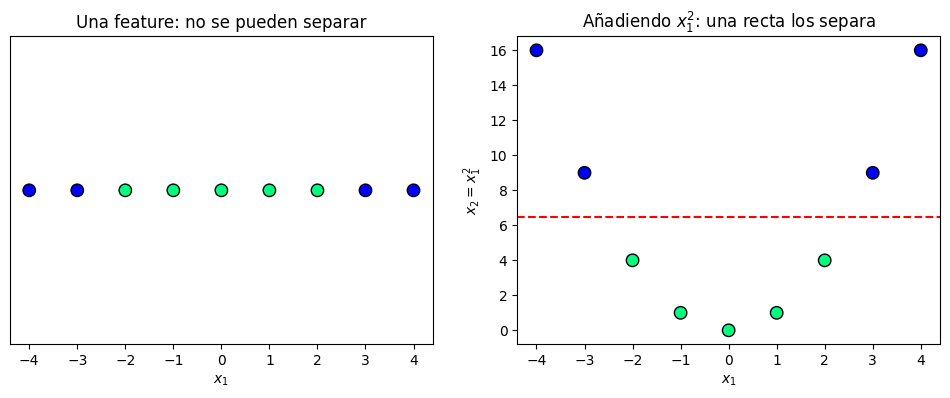

In [15]:
x_1d = np.linspace(-4, 4, 9)
y_1d = np.array([0, 0, 1, 1, 1, 1, 1, 0, 0])

fig, axs = plt.subplots(1, 2, figsize=(12, 4))
axs[0].scatter(x_1d, np.zeros_like(x_1d), c=y_1d, s=80, cmap='winter', edgecolors='k')
axs[0].set_yticks([]); axs[0].set_xlabel("$x_1$")
axs[0].set_title("Una feature: no se pueden separar")

axs[1].scatter(x_1d, x_1d**2, c=y_1d, s=80, cmap='winter', edgecolors='k')
axs[1].axhline(6.5, color="red", linestyle="--")
axs[1].set_xlabel("$x_1$"); axs[1].set_ylabel("$x_2 = x_1^2$")
axs[1].set_title("Añadiendo $x_1^2$: una recta los separa")
plt.show()

Eso es lo que hacen los kernels, con la ventaja de que no hace falta calcular las nuevas features: el SVM trabaja como si los datos estuvieran en ese espacio ampliado (es lo que se conoce como *kernel trick*).

Vamos a ver dos kernels (no hace falta que te aprendas las fórmulas que siguen: están por completitud teórica). Ya hemos visto otro más, el "linear", que es el que hemos aplicado antes.

**Kernel polinómico**: Transformamos la dimensión de entrada a través de un polinomio de grado *d*. Por ejemplo, para $d=2$: 
$(x_1, x_2) \rightarrow (x_1, x_2, x_1x_2, x_1^2, x_2^2)$  

**Kernel RBF (Radial Basis Function)**: equivale a trasladar los datos a un espacio de dimensión infinita. En la práctica, el kernel no transforma cada punto por separado, sino que mide la similitud entre dos puntos $x$ y $x'$:  
$K(x, x') = \exp(-\gamma||x - x'||^2)$

Veamos algún ejemplo con datos no linealmente separables

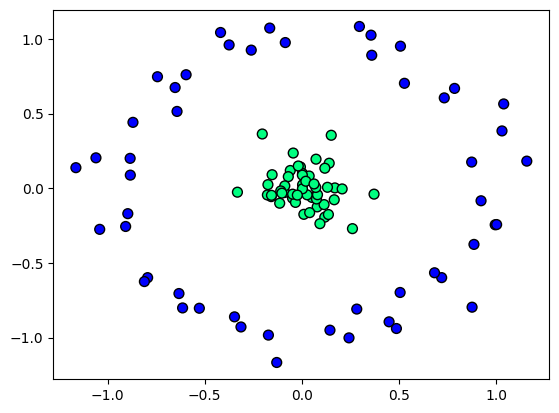

In [16]:
from sklearn.datasets import make_circles
X, y = make_circles(100, factor=.1, noise=.1, random_state=42)

plt.scatter(X[:, 0], X[:, 1], c=y, s=50, cmap='winter',edgecolors='k');

**Kernel lineal**

In [17]:
from sklearn.svm import SVC 
clf = SVC(kernel='linear').fit(X,y) # Se instancia igual, solo hay que cambiar el argumento 'kernel'

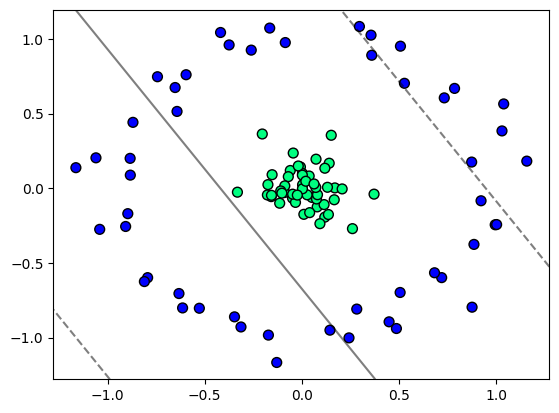

In [18]:
plt.scatter(X[:, 0], X[:, 1], c=y, s=50, cmap='winter',edgecolors='k')
plot_svc_decision_function(clf, plot_support=False);

**Kernel polinómico de grado 2**

In [19]:
clf = SVC(kernel='poly', degree=2,C=1e6)
clf.fit(X,y)

,"C C: float, default=1.0Regularization parameter. The strength of the regularization isinversely proportional to C. Must be strictly positive. The penaltyis a squared l2 penalty. For an intuitive visualization of the effectsof scaling the regularization parameter C, see:ref:`sphx_glr_auto_examples_svm_plot_svm_scale_c.py`.",1000000.0
,"kernel kernel: {'linear', 'poly', 'rbf', 'sigmoid', 'precomputed'} or callable, default='rbf'Specifies the kernel type to be used in the algorithm. Ifnone is given, 'rbf' will be used. If a callable is given it is used topre-compute the kernel matrix from data matrices; that matrix should bean array of shape ``(n_samples, n_samples)``. For an intuitivevisualization of different kernel types see:ref:`sphx_glr_auto_examples_svm_plot_svm_kernels.py`.",'poly'
,"degree degree: int, default=3Degree of the polynomial kernel function ('poly').Must be non-negative. Ignored by all other kernels.",2
,"gamma gamma: {'scale', 'auto'} or float, default='scale'Kernel coefficient for 'rbf', 'poly' and 'sigmoid'.- if ``gamma='scale'`` (default) is passed then it uses 1 / (n_features * X.var()) as value of gamma,- if 'auto', uses 1 / n_features- if float, must be non-negative... versionchanged:: 0.22 The default value of ``gamma`` changed from 'auto' to 'scale'.",'scale'
,"coef0 coef0: float, default=0.0Independent term in kernel function.It is only significant in 'poly' and 'sigmoid'.",0.0
,"shrinking shrinking: bool, default=TrueWhether to use the shrinking heuristic.See the :ref:`User Guide <shrinking_svm>`.",True
,"probability probability: bool, default=FalseWhether to enable probability estimates. This must be enabled priorto calling `fit`, will slow down that method as it internally uses5-fold cross-validation, and `predict_proba` may be inconsistent with`predict`. Read more in the :ref:`User Guide <scores_probabilities>`...deprecated:: 1.9 The `probability` parameter is deprecated and will be removed in 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`.",'deprecated'
,"tol tol: float, default=1e-3Tolerance for stopping criterion.",0.001
,"cache_size cache_size: float, default=200Specify the size of the kernel cache (in MB).",200
,"class_weight class_weight: dict or 'balanced', default=NoneSet the parameter C of class i to class_weight[i]*C forSVC. If not given, all classes are supposed to haveweight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.",None
,"verbose verbose: bool, default=FalseEnable verbose output. Note that this setting takes advantage of aper-process runtime setting in libsvm that, if enabled, may not workproperly in a multithreaded context.",False


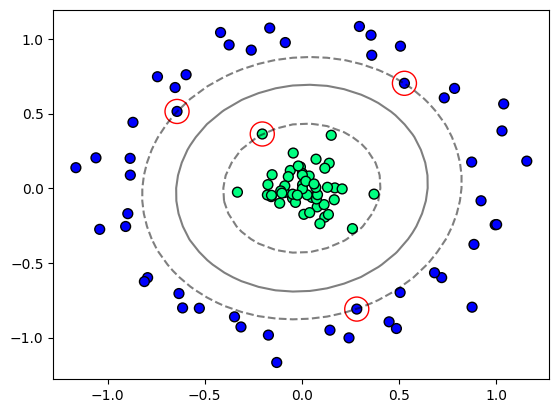

In [20]:
plt.scatter(X[:, 0], X[:, 1], c=y, s=50, cmap='winter',edgecolors='k')
plot_svc_decision_function(clf)

**Kernel RBF**

In [21]:
clf = SVC(kernel='rbf', C=1e6)
clf.fit(X,y)

,"C C: float, default=1.0Regularization parameter. The strength of the regularization isinversely proportional to C. Must be strictly positive. The penaltyis a squared l2 penalty. For an intuitive visualization of the effectsof scaling the regularization parameter C, see:ref:`sphx_glr_auto_examples_svm_plot_svm_scale_c.py`.",1000000.0
,"kernel kernel: {'linear', 'poly', 'rbf', 'sigmoid', 'precomputed'} or callable, default='rbf'Specifies the kernel type to be used in the algorithm. Ifnone is given, 'rbf' will be used. If a callable is given it is used topre-compute the kernel matrix from data matrices; that matrix should bean array of shape ``(n_samples, n_samples)``. For an intuitivevisualization of different kernel types see:ref:`sphx_glr_auto_examples_svm_plot_svm_kernels.py`.",'rbf'
,"degree degree: int, default=3Degree of the polynomial kernel function ('poly').Must be non-negative. Ignored by all other kernels.",3
,"gamma gamma: {'scale', 'auto'} or float, default='scale'Kernel coefficient for 'rbf', 'poly' and 'sigmoid'.- if ``gamma='scale'`` (default) is passed then it uses 1 / (n_features * X.var()) as value of gamma,- if 'auto', uses 1 / n_features- if float, must be non-negative... versionchanged:: 0.22 The default value of ``gamma`` changed from 'auto' to 'scale'.",'scale'
,"coef0 coef0: float, default=0.0Independent term in kernel function.It is only significant in 'poly' and 'sigmoid'.",0.0
,"shrinking shrinking: bool, default=TrueWhether to use the shrinking heuristic.See the :ref:`User Guide <shrinking_svm>`.",True
,"probability probability: bool, default=FalseWhether to enable probability estimates. This must be enabled priorto calling `fit`, will slow down that method as it internally uses5-fold cross-validation, and `predict_proba` may be inconsistent with`predict`. Read more in the :ref:`User Guide <scores_probabilities>`...deprecated:: 1.9 The `probability` parameter is deprecated and will be removed in 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`.",'deprecated'
,"tol tol: float, default=1e-3Tolerance for stopping criterion.",0.001
,"cache_size cache_size: float, default=200Specify the size of the kernel cache (in MB).",200
,"class_weight class_weight: dict or 'balanced', default=NoneSet the parameter C of class i to class_weight[i]*C forSVC. If not given, all classes are supposed to haveweight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.",None
,"verbose verbose: bool, default=FalseEnable verbose output. Note that this setting takes advantage of aper-process runtime setting in libsvm that, if enabled, may not workproperly in a multithreaded context.",False


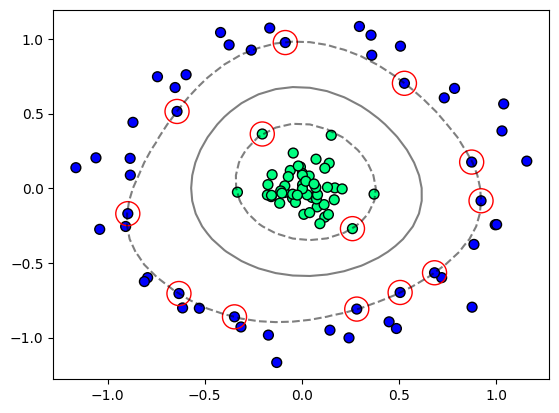

In [22]:
plt.scatter(X[:, 0], X[:, 1], c=y, s=50, cmap='winter',edgecolors='k')
plot_svc_decision_function(clf)

### SVM en regresión

Aunque SVM es conocido por ser un modelo de clasificación, también puede utilizarse en regresión (`SVR`, *Support Vector Regression*).

In [23]:
import numpy as np
from sklearn.svm import SVR
from sklearn.metrics import mean_squared_error

La idea se "invierte" respecto a la clasificación: en lugar de buscar la calle más ancha posible **sin** puntos dentro, el SVR busca un "tubo" de anchura $\pm\varepsilon$ alrededor de la predicción que contenga **el máximo** de puntos. Los errores de los puntos que caen dentro del tubo no cuentan; solo penalizan los que quedan fuera, que son los vectores de soporte. La anchura del tubo se controla con el hiperparámetro `epsilon`:

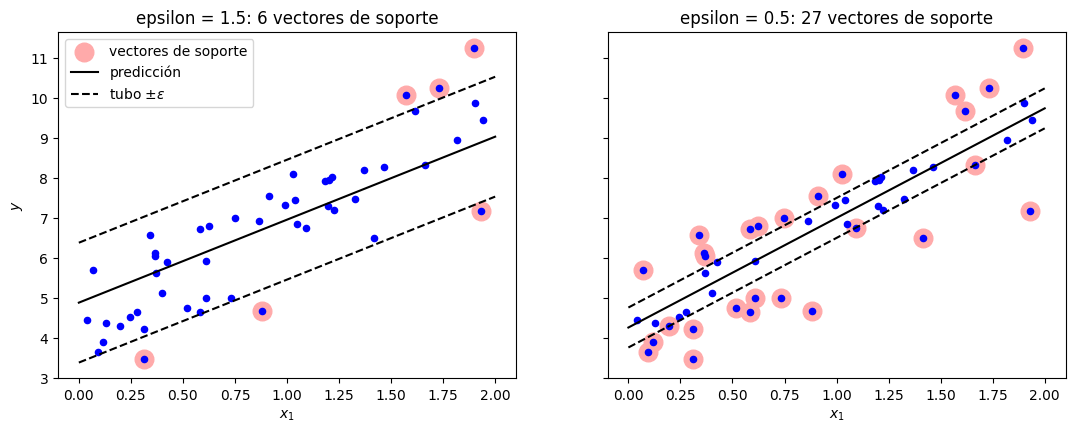

In [24]:
np.random.seed(42)
x_lin = 2 * np.random.rand(50, 1)
y_lin = 4 + 3 * x_lin.ravel() + np.random.randn(50)
x_plot = np.linspace(0, 2, 100).reshape(-1, 1)

fig, axs = plt.subplots(1, 2, figsize=(13, 4.5), sharey=True)
for ax, eps in zip(axs, [1.5, 0.5]):
    svr_lin = SVR(kernel="linear", epsilon=eps).fit(x_lin, y_lin)
    y_plot = svr_lin.predict(x_plot)
    ax.scatter(x_lin[svr_lin.support_], y_lin[svr_lin.support_], s=180, facecolors="#FFAAAA", label="vectores de soporte")
    ax.scatter(x_lin, y_lin, color="blue", s=20)
    ax.plot(x_plot, y_plot, "k-", label="predicción")
    ax.plot(x_plot, y_plot + eps, "k--", label="tubo $\\pm\\varepsilon$")
    ax.plot(x_plot, y_plot - eps, "k--")
    ax.set_title(f"epsilon = {eps}: {len(svr_lin.support_)} vectores de soporte")
    ax.set_xlabel("$x_1$")
axs[0].set_ylabel("$y$"); axs[0].legend(loc="upper left")
plt.show()

Con un tubo ancho (epsilon = 1.5) casi todos los puntos caen dentro y solo 6 son vectores de soporte; con un tubo estrecho (epsilon = 0.5) quedan fuera muchos más (27). Añadir puntos dentro del tubo no cambia el modelo: solo importan los que están fuera o en el borde.

Con datos no lineales se usa un kernel, igual que en clasificación. Por defecto el `SVR` usa el RBF:

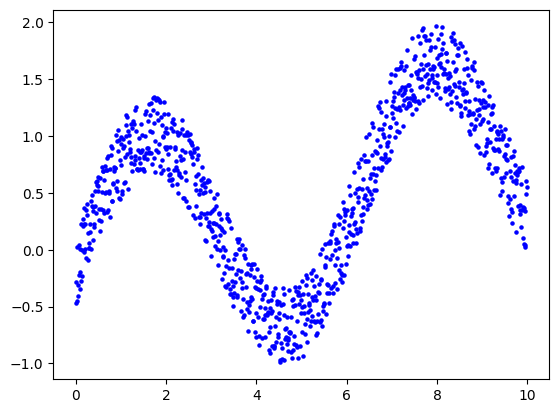

In [25]:
np.random.seed(21)

N =1000

def makeData(x):
    r = [a/10 for a in x]
    y = np.sin(x)+np.random.uniform(-0.5, 0.2, len(x))
    return np.array(y+r)

x = [i/100 for i in range(N)]
y = makeData(x)
x = np.array(x).reshape(-1,1)

plt.scatter(x,y,s=5,color="blue");

In [26]:
svr = SVR() # Por defecto el kernel es el RBF
svr.fit(x,y)

,"kernel kernel: {'linear', 'poly', 'rbf', 'sigmoid', 'precomputed'} or callable, default='rbf'Specifies the kernel type to be used in the algorithm.If none is given, 'rbf' will be used. If a callable is given it isused to precompute the kernel matrix.For an intuitive visualization of different kernel typessee :ref:`sphx_glr_auto_examples_svm_plot_svm_regression.py`",'rbf'
,"degree degree: int, default=3Degree of the polynomial kernel function ('poly').Must be non-negative. Ignored by all other kernels.",3
,"gamma gamma: {'scale', 'auto'} or float, default='scale'Kernel coefficient for 'rbf', 'poly' and 'sigmoid'.- if ``gamma='scale'`` (default) is passed then it uses 1 / (n_features * X.var()) as value of gamma,- if 'auto', uses 1 / n_features- if float, must be non-negative... versionchanged:: 0.22 The default value of ``gamma`` changed from 'auto' to 'scale'.",'scale'
,"coef0 coef0: float, default=0.0Independent term in kernel function.It is only significant in 'poly' and 'sigmoid'.",0.0
,"tol tol: float, default=1e-3Tolerance for stopping criterion.",0.001
,"C C: float, default=1.0Regularization parameter. The strength of the regularization isinversely proportional to C. Must be strictly positive.The penalty is a squared l2. For an intuitive visualization of theeffects of scaling the regularization parameter C, see:ref:`sphx_glr_auto_examples_svm_plot_svm_scale_c.py`.",1.0
,"epsilon epsilon: float, default=0.1Epsilon in the epsilon-SVR model. It specifies the epsilon-tubewithin which no penalty is associated in the training loss functionwith points predicted within a distance epsilon from the actualvalue. Must be non-negative.",0.1
,"shrinking shrinking: bool, default=TrueWhether to use the shrinking heuristic.See the :ref:`User Guide <shrinking_svm>`.",True
,"cache_size cache_size: float, default=200Specify the size of the kernel cache (in MB).",200
,"verbose verbose: bool, default=FalseEnable verbose output. Note that this setting takes advantage of aper-process runtime setting in libsvm that, if enabled, may not workproperly in a multithreaded context.",False
,"max_iter max_iter: int, default=-1Hard limit on iterations within solver, or -1 for no limit.",-1


In [27]:
yfit = svr.predict(x)

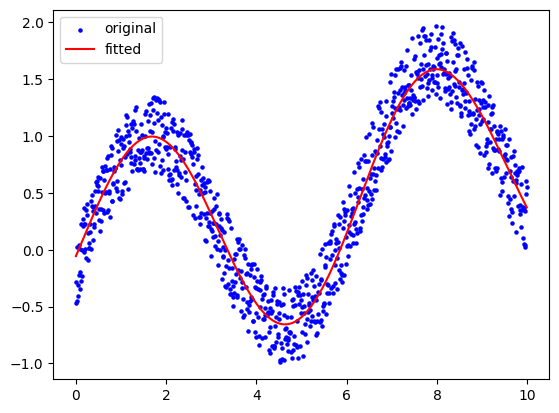

In [28]:
plt.scatter(x, y, s=5, color="blue", label='original')
plt.plot(x, yfit, color="red", label='fitted')
plt.legend()
plt.show()

In [29]:
# Ojo: evaluamos contra los mismos datos de entrenamiento, solo para ver lo bien que se ajusta (no es una medida de generalización)
score = svr.score(x, y)
print('R-squared:', score)
print('MSE:', mean_squared_error(y,yfit))

R-squared: 0.9201610722643554
MSE: 0.041676600207571246


---

*Las figuras de sensibilidad a la escala y a outliers, el efecto de C, la intuición de los kernels con una sola feature y el tubo del SVR están adaptadas del capítulo 5 de* Hands-On Machine Learning with Scikit-Learn, Keras & TensorFlow *(Aurélien Géron), cuyo código se publica con licencia Apache 2.0.*